# Generic-ballot scenarios: House, Senate and Kalshi

The production 2026 forecasts rerun with the generic ballot moved **4 points toward Republicans** and **4 points toward Democrats**, and what each does to the value of Kalshi positions. Code: `src/house/forecast.py` and `src/senate/forecast.py` (the production pipelines, run with `shift`), `src/congress/report.py`, and `src/scenarios/generic_ballot.py` (Kalshi). The full forecast, `notebooks/full-forecast/full_forecast_2026.ipynb`, runs the same shifts on the adjusted submission.

- **The shift.** 2026's `gen_margin_raw` (FiftyPlusOne's election-eve D − R margin, D+8.7) becomes D+4.7 or D+12.7. Everything downstream is rerun unchanged, and nothing imposes how far a race moves.
  - **House:** each race moves by Stage 1's own pass-through, 0.85 × Model A's `gen_margin_raw` coefficient (Model B has no generic-ballot term). The forecast is section 5 of `notebooks/house/stage2/02_monte_carlo.ipynb`.
  - **Senate:** the fundamentals move by Senate Stage 1's coefficient. The Stage 2 blend holds polls and expert ratings fixed, so a polled race moves by 0.37 of that and an unpolled one by 0.65. The three independent-vs-R races are centered on expert ratings alone, so they don't move. The forecast is `notebooks/senate/stage2/03_monte_carlo.ipynb`, S-M0.
  - **Only the input moves.** If the generic ballot were really 4 points off, the Senate polls would probably miss in the same direction. This doesn't model that, so the Senate moves less than a true environment shift would move it.
- **Draws:** each chamber uses its notebook's seed in every scenario. The error draws are identical, so the scenarios differ only by the shift.
- **Error model:** fit on out-of-sample residuals from earlier years (House 2018–2024, Senate 2016–2024). A 2026 shift doesn't change it, so it is estimated once.
- **Model only:** these are the model's own rows, with no margin adjustments (`data/reference/margin_adjustments_2026.csv`). The full forecast applies those.
- **Kalshi:** one saved price pull (`data/processed/kalshi/kalshi_markets_2026.csv`), held fixed across the scenarios. The question is what the model's probabilities say those prices are worth: the filed bets (`kelly_bets_2026.csv`) revalued, and new Kelly bets sized on each scenario.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
import house.regression as hr
from congress import report
from house import forecast as house_forecast
from house import simulation
from kalshi import optimizer
from scenarios import generic_ballot as gb
from senate import forecast as senate_forecast

pd.set_option("display.width", 220)

In [2]:
# Scenarios: points added to 2026's gen_margin_raw (D - R), so negative is toward Republicans
SHIFTS = {"R+4": -4.0, "baseline": 0.0, "D+4": 4.0}
BASELINE = "baseline"

# Kalshi: src/kalshi/run.py's settings
TOSSUP_LOW, TOSSUP_HIGH = 0.4, 0.6
BANKROLL = 1000.0
KELLY_FRACTION = 0.25
MIN_EDGE = 0.02

# The House and Senate settings are the production ones (src/house/forecast.py, src/senate/forecast.py)

In [3]:
house_inputs = house_forecast.load_inputs()    # data, the H0 error model, the same-party top-two predictions
senate_inputs = senate_forecast.load_inputs()
markets = pd.read_csv(ROOT / "data/processed/kalshi/kalshi_markets_2026.csv")  # the saved Kalshi pull
filed_bets = pd.read_csv(ROOT / "data/processed/kalshi/kelly_bets_2026.csv")    # run.py's bets on the submission

## 1. The scenarios

Each chamber's production forecast with `shift` and nothing else: production Senate weights, no margin adjustments. That makes it the model's own forecast. The error models and the same-party top-two predictions don't depend on 2026's generic ballot, so they are loaded once. The baseline must reproduce each chamber's saved model track file exactly (`congress_track_house_2026.csv`, `congress_track_senate_2026.csv`).

In [4]:
house = {name: house_forecast.run(house_inputs, shift=shift) for name, shift in SHIFTS.items()}
senate = {name: senate_forecast.run(senate_inputs, shift=shift) for name, shift in SHIFTS.items()}

pd.testing.assert_frame_equal(house[BASELINE].track, pd.read_csv(house_forecast.MODEL_TRACK_PATH), check_dtype=False)
pd.testing.assert_frame_equal(senate[BASELINE].track, pd.read_csv(senate_forecast.MODEL_TRACK_PATH), check_dtype=False)
print("baselines reproduce the saved House and Senate track files")

baselines reproduce the saved House and Senate track files


**Pass-through:** how far each race's center moved, per point of generic ballot. It is set by the fitted coefficients and the blend weights, not by this notebook.

In [5]:
base_house = house[BASELINE].point.set_index(hr.KEY)
base_senate = senate[BASELINE].point
pass_through = {}
for name, shift in SHIFTS.items():
    if shift == 0:
        continue
    moved = (house[name].point.set_index(hr.KEY)["prediction"] - base_house["prediction"]) / shift
    pass_through[("House", name)] = moved.groupby(base_house["prediction_source"]).describe()[["count", "mean", "min", "max"]]
    moved = (senate[name].point["center"] - base_senate["center"]) / shift
    group = base_senate["seat_type"] + " / " + base_senate["weight_case"]
    pass_through[("Senate", name)] = moved.groupby(group).describe()[["count", "mean", "min", "max"]]
pd.concat(pass_through, names=["chamber", "scenario", "races"]).query("count > 0").round(3)  # rule-decided races have no margin

count   mean    min    max
chamber scenario races                                                    
House   R+4      house_ensemble_ab_85_15        417.0  0.665  0.665  0.665
Senate  R+4      dem_nominee / no_polling        21.0  0.542  0.542  0.542
                 dem_nominee / polling           11.0  0.309  0.309  0.309
                 independent_only / no_polling    3.0  0.000 -0.000 -0.000
House   D+4      house_ensemble_ab_85_15        417.0  0.665  0.665  0.665
Senate  D+4      dem_nominee / no_polling        21.0  0.542  0.542  0.542
                 dem_nominee / polling           11.0  0.309  0.309  0.309
                 independent_only / no_polling    3.0  0.000  0.000  0.000

## 2. Chambers

In [6]:
summary = report.chamber_summary(house, senate, baseline=BASELINE)
summary.T

,R+4,baseline,D+4
generic ballot (D - R),4.7,8.7,12.7
House: mean race shift,-2.658659,0.0,2.658659
House: median D seats,223.0,232.0,242.0
House: D seats 10%-90%,214–234,222–244,230–255
House: P(D 218+),0.79525,0.961625,0.99305
House: races called D,223,227,240
Senate: mean race shift (D nominees),-1.847776,0.0,1.847776
Senate: median D-caucus seats,51.0,52.0,52.0
Senate: D-caucus seats 10%-90%,48–53,49–54,50–55
Senate: P(D control),0.575675,0.70845,0.816725


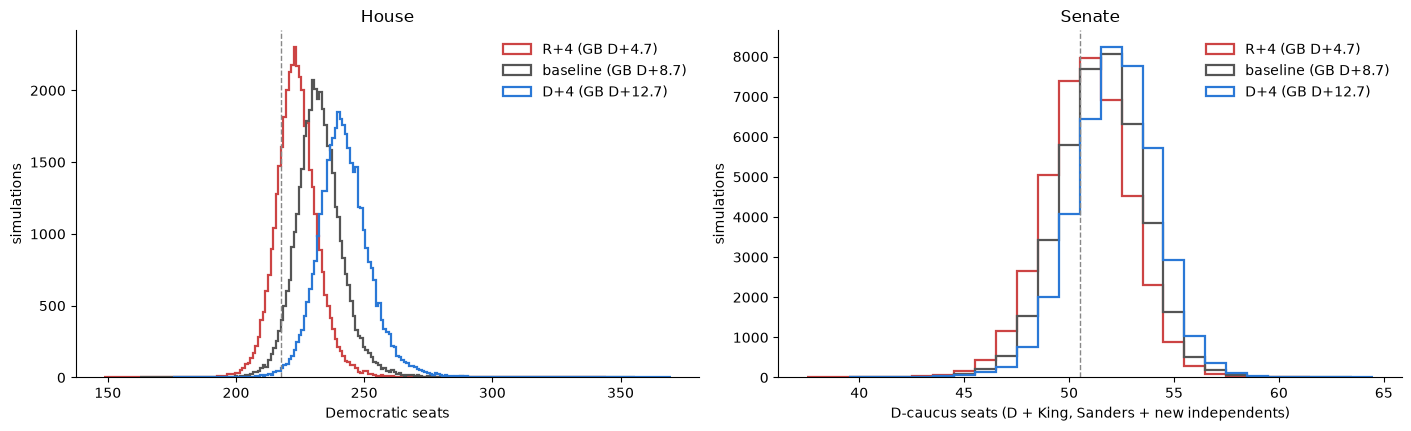

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), layout="constrained")
colors = {"R+4": "#c44", "baseline": "#555", "D+4": "#2a78d6"}
for name, h in house.items():
    seats = h.draws.seats(simulation.DEM)
    axes[0].hist(seats, bins=np.arange(seats.min() - 0.5, seats.max() + 1.5), histtype="step", lw=1.6,
                 color=colors[name], label=f"{name} (GB D{h.generic_ballot:+.1f})")
axes[0].axvline(report.HOUSE_MAJORITY - 0.5, color="#888", lw=1, ls="--")
axes[0].set(xlabel="Democratic seats", ylabel="simulations", title="House")
for name, s in senate.items():
    seats = report.senate_dem_caucus(s.counts)
    axes[1].hist(seats, bins=np.arange(seats.min() - 0.5, seats.max() + 1.5), histtype="step", lw=1.6,
                 color=colors[name], label=f"{name} (GB D{s.generic_ballot:+.1f})")
axes[1].axvline(50.5, color="#888", lw=1, ls="--")
axes[1].set(xlabel="D-caucus seats (D + King, Sanders + new independents)", ylabel="simulations", title="Senate")
for ax in axes:
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 3. Races whose call changes

Every House and Senate race whose predicted winner differs from the baseline in either scenario. Five of them are overridden in the submission (TX-35, IA-02, ME-02, WI-03, AK-SEN). The baseline here shows the model's call, not the override.

In [8]:
tracks = {name: pd.concat([house[name].track, senate[name].track], ignore_index=True) for name in SHIFTS}
flips = report.flipped_races(tracks, baseline=BASELINE)
overridden = set(pd.read_csv(ROOT / "data/reference/track_overrides_2026.csv")["race_id"])
display(Markdown(f"**{len(flips)} races change call** (overridden in the submission: "
                 f"{', '.join(sorted(overridden & set(flips.index)))})"))
flips.round(3)

**20 races change call** (overridden in the submission: AK-SEN, IA-02, ME-02, TX-35, WI-03)

candidate_name                                         predicted_winner_party              win_probability                
                              R+4            baseline                 D+4                    R+4 baseline D+4             R+4 baseline    D+4
race_id                                                                                                                                      
AL-02               Rhett Marques       Rhett Marques     Shomari Figures                      R        R   D           0.762    0.605  0.576
CO-03                   Jeff Hurd           Jeff Hurd       Dwayne Romero                      R        R   D           0.785    0.631  0.551
FL-09                   Dan Green           Dan Green         Darren Soto                      R        R   D           0.815    0.674  0.508
FL-22                 Casey Askar         Casey Askar         Pia Dandiya                      R        R   D           0.704    0.528  0.650
IA-01    Mariannette Miller-Meeks  Christina Bohannan  Christina Bohannan                      R        D   D           0.515    0.664  0.809
IA-02                Joe Mitchell        Joe Mitchell       Lindsay James                      R        R   D           0.718    0.544  0.637
ME-02                 Paul LePage         Paul LePage      Matthew Dunlap                      R        R   D           0.736    0.570  0.610
MI-04               Bill Huizenga       Bill Huizenga         Sean McCann                      R        R   D           0.764    0.605  0.583
MT-01                 Aaron Flint         Aaron Flint         Sam Forstag                      R        R   D           0.817    0.674  0.502
NC-01             Laurie Buckhout           Don Davis           Don Davis                      R        D   D           0.547    0.634  0.785
NY-01                 Nick LaLota         Nick LaLota       Chris Gallant                      R        R   D           0.822    0.677  0.502
PA-01           Brian Fitzpatrick          Bob Harvie          Bob Harvie                      R        D   D           0.569    0.613  0.769
PA-08               Rob Bresnahan       Rob Bresnahan      Paige Cognetti                      R        R   D           0.702    0.530  0.648
TX-35           Carlos De La Cruz   Carlos De La Cruz       Johnny Garcia                      R        R   D           0.683    0.506  0.674
VA-01                 Rob Wittman         Rob Wittman      Shannon Taylor                      R        R   D           0.684    0.504  0.677
WI-01                 Bryan Steil         Bryan Steil     Mitchell Berman                      R        R   D           0.712    0.542  0.641
WI-03           Derrick Van Orden       Rebecca Cooke       Rebecca Cooke                      R        D   D           0.596    0.586  0.752
AK-SEN            Dan S. Sullivan     Dan S. Sullivan        Mary Peltola                      R        R   D           0.624    0.542  0.542
IA-SEN              Ashley Hinson       Ashley Hinson          Josh Turek                      R        R   D           0.653    0.574  0.512
KS-SEN             Roger Marshall      Roger Marshall       Adam Hamilton                      R        R   D           0.618    0.538  0.545

## 4. Kalshi

Prices are fixed at the saved pull. Each scenario's probabilities are the belief, by `run.py`'s rule:
- On the submitted candidate's market, P(YES) is the win probability.
- In a two-market race, the other market gets one minus that.

Dollar figures are expected profit in that scenario's world, net of Kalshi's taker fee.

- **Filed bets:** the 27 positions in `kelly_bets_2026.csv`, with contracts and costs as filed, revalued under each scenario. `run.py` sized them on the submission as filed, so they include the overrides. Their filed expected profit is shown for reference.
- **Re-sized:** `tossups` and `kelly_bets` rerun on each scenario's probabilities, with the same bankroll, Kelly fraction and minimum edge.

These numbers treat the model as the truth. A large expected profit mostly means the model and Kalshi disagree. It says nothing about which of them is right.

In [9]:
kalshi = {name: gb.kalshi_scenario(tracks[name], markets, low=TOSSUP_LOW, high=TOSSUP_HIGH, bankroll=BANKROLL,
                                   kelly_fraction=KELLY_FRACTION, min_edge=MIN_EDGE)
          for name in SHIFTS}
kalshi_table = gb.kalshi_summary(kalshi, filed_bets)
display(Markdown(f"**Filed bets as filed** (submission probabilities, overrides included): stake "
                 f"${filed_bets['stake'].sum():,.2f}, expected profit ${filed_bets['expected_profit'].sum():,.2f}"))
kalshi_table.T.round(2)

**Filed bets as filed** (submission probabilities, overrides included): stake $786.95, expected profit $590.96

,R+4,baseline,D+4
fixed bets: stake,786.95,786.95,786.95
fixed bets: expected profit,863.96,674.79,433.09
fixed bets: losing in expectation,0.00,0.00,7.00
fixed bets: unpriced,0.00,0.00,0.00
re-sized bets: n,33.00,30.00,27.00
re-sized bets: stake,818.76,785.65,735.88
re-sized bets: expected profit,796.49,548.26,434.79


In [10]:
# Each filed bet's belief and expected profit under each scenario, worst first under D+4
by_bet = pd.concat({name: optimizer.expected_profit(filed_bets, k.beliefs).set_index(["race_id", "candidate", "side"])
                    [["belief", "edge", "expected_profit"]] for name, k in kalshi.items()}, axis=1)
filed = filed_bets.set_index(["race_id", "candidate", "side"])[["price", "contracts", "expected_profit"]]
by_bet = pd.concat({"filed": filed}, axis=1).join(by_bet)
by_bet.sort_values(("D+4", "expected_profit")).round(3)

filed                              R+4                        baseline                           D+4                       
                                price contracts expected_profit belief   edge expected_profit   belief   edge expected_profit belief   edge expected_profit
race_id candidate          side                                                                                                                            
CO-03   Jeff Hurd          yes   0.54        20           1.463  0.785  0.228           4.559    0.631  0.073           1.463  0.449 -0.109          -2.176
AL-02   Rhett Marques      yes   0.47        32           3.776  0.762  0.274           8.776    0.605  0.118           3.776  0.424 -0.064          -2.040
MO-02   Fred Wellman       no    0.61        17           0.997  0.823  0.197           3.343    0.685  0.059           0.997  0.509 -0.118          -1.999
FL-22   Casey Askar        yes   0.38        37           4.864  0.704  0.308          11.394    0.528  0.131           4.864  0.350 -0.047          -1.738
WI-01   Bryan Steil        yes   0.49         9           0.311  0.712  0.204           1.839    0.542  0.035           0.311  0.359 -0.148          -1.334
IA-SEN  Ashley Hinson      yes   0.51        12           0.562  0.653  0.126           1.507    0.574  0.047           0.562  0.488 -0.039          -0.469
SC-01   Nancy S. Lacore    no    0.53        46           7.768  0.844  0.297          13.664    0.716  0.169           7.768  0.546 -0.002          -0.072
CA-04   Eric Jones         no    0.57         1           0.335  0.922  0.335           0.335    0.922  0.335           0.335  0.922  0.335           0.335
VA-05   Tom Perriello      no    0.59         4           1.103  0.943  0.336           1.344    0.883  0.276           1.103  0.780  0.173           0.692
CA-40   Young Kim          no    0.50         5           1.674  0.852  0.335           1.674    0.852  0.335           1.674  0.852  0.335           1.674
MT-01   Sam Forstag        no    0.40        25           6.433  0.817  0.400          10.013    0.674  0.257           6.433  0.498  0.081           2.026
KS-SEN  Roger Marshall     yes   0.37        43           6.527  0.618  0.232           9.982    0.538  0.152           6.527  0.455  0.068           2.935
TX-35   Johnny C. Garcia   no    0.27        74          16.419  0.683  0.399          29.534    0.506  0.222          16.419  0.326  0.042           3.130
OH-15   Don Leonard        no    0.60        48          10.139  0.914  0.298          14.286    0.828  0.211          10.139  0.689  0.072           3.457
IA-02   Lindsay James      no    0.29        76          18.184  0.718  0.414          31.431    0.544  0.239          18.184  0.363  0.059           4.468
VA-01   Rob Wittman        yes   0.24        90          22.636  0.684  0.431          38.766    0.504  0.252          22.636  0.323  0.070           6.330
MN-01   Jake Johnson       no    0.60        74          19.220  0.940  0.323          23.909    0.877  0.260          19.220  0.765  0.148          10.958
NC-13   Paul Barringer     no    0.60        41          13.418  0.974  0.357          14.651    0.944  0.327          13.418  0.886  0.269          11.029
AZ-02   Jonathan Nez       no    0.55        73          20.840  0.928  0.360          26.295    0.853  0.285          20.840  0.728  0.161          11.760
CO-05   Jeff Crank         yes   0.52        79          23.003  0.914  0.377          29.777    0.829  0.291          23.003  0.695  0.157          12.417
NV-02   David Flippo       yes   0.52        84          26.005  0.924  0.387          32.481    0.847  0.310          26.005  0.720  0.183          15.372
WI-03   Derrick Van Orden  yes   0.13       157          43.337  0.596  0.458          71.962    0.414  0.276          43.337  0.248  0.110          17.295
NC-03   Raymond Smith Jr.  no    0.60        89          27.543  0.965  0.348          31.012    0.926  0.309          27.543  0.853

In [11]:
# Re-sized bets: each scenario's positions side by side (blank = no bet in that race)
resized = pd.concat({name: k.bets.set_index("race_id")[["candidate", "side", "price", "belief", "contracts",
                                                         "expected_profit"]] for name, k in kalshi.items()}, axis=1)
resized.round(3)

R+4                                                            baseline                                                             D+4                                            
                        candidate side  price belief contracts expected_profit              candidate side price belief contracts expected_profit           candidate side price belief contracts expected_profit
race_id                                                                                                                                                                                                          
TX-23          Katy Padilla Stout   no  0.590  0.974      79.0          28.965     Katy Padilla Stout   no  0.59  0.944      96.0          32.318  Katy Padilla Stout   no  0.59  0.886     110.0          30.681
NC-13              Paul Barringer   no  0.600  0.974      41.0          14.651         Paul Barringer   no  0.60  0.944      41.0          13.418      Paul Barringer   no  0.60  0.886      41.0          11.029
NC-03                 Greg Murphy  yes  0.600  0.965      76.0          26.482            Greg Murphy  yes  0.60  0.926      89.0          27.543   Raymond Smith Jr.   no  0.60  0.853      94.0          22.217
NJ-02               Jeff Van Drew  yes  0.530  0.958      85.0          34.860          Jeff Van Drew  yes  0.53  0.913     100.0          36.546       Jeff Van Drew  yes  0.53  0.828     107.0          30.074
KY-06                  Zach Dembo   no  0.410  0.928     105.0          52.596         Ralph Alvarado  yes  0.41  0.853     118.0          50.252      Ralph Alvarado  yes  0.41  0.728     116.0          34.898
VA-05               Tom Perriello   no  0.590  0.943       4.0           1.344          Tom Perriello   no  0.59  0.883       4.0           1.103       Tom Perriello   no  0.59  0.780       4.0           0.692
MN-01                Jake Johnson   no  0.600  0.940      70.0          22.617           Jake Johnson   no  0.60  0.877      74.0          19.220        Jake Johnson   no  0.60  0.765      59.0           8.736
NV-02     Teresa Benitez-Thompson   no  0.520  0.924      80.0          30.934           David Flippo  yes  0.52  0.847      84.0          26.005        David Flippo  yes  0.52  0.720      69.0          12.627
AZ-02                Jonathan Nez   no  0.550  0.928      73.0          26.295           Jonathan Nez   no  0.55  0.853      73.0          20.840        Jonathan Nez   no  0.55  0.728      62.0           9.988
CO-05              Jessica Killin   no  0.520  0.914      78.0          29.400         Jessica Killin   no  0.52  0.829      79.0          23.003          Jeff Crank  yes  0.52  0.695      59.0           9.274
CA-04                  Eric Jones   no  0.570  0.922       1.0           0.335             Eric Jones   no  0.57  0.922       1.0           0.335          Eric Jones   no  0.57  0.922       1.0           0.335
OH-15                 Don Leonard   no  0.600  0.914      48.0          14.286            Don Leonard   no  0.60  0.828      48.0          10.139         Don Leonard   no  0.60  0.689      28.0           2.017
CA-40                   Young Kim   no  0.500  0.852       5.0           1.674              Young Kim   no  0.50  0.852       5.0           1.674           Young Kim   no  0.50  0.852       5.0           1.674
MT-01                 Sam Forstag   no  0.400  0.817      25.0          10.013            Sam Forstag   no  0.40  0.674      25.0           6.433         Sam Forstag   no  0.40  0.498      25.0           2.026
SC-01       Jenny Costa Honeycutt  yes  0.530  0.844      61.0          18.119  Jenny Costa Honeycutt  yes  0.53  0.716      46.0           7.768                 NaN  NaN   NaN    NaN       NaN             NaN
AL-02               Rhett Marques  yes  0.470  0.762      56.0          15.359          Rhett Marques  yes  0.47  0.605      32.0           3.776     Shomari Figures  yes  0.53  0.576      11.0           0.317
WI-03           Derrick Van Orden  yes  

## 5. Outputs

In [12]:
OUT_DIR = ROOT / "data/processed/scenarios"
OUT_DIR.mkdir(parents=True, exist_ok=True)
outputs = {
    "generic_ballot_chambers.csv": summary.rename_axis("scenario").reset_index(),
    "generic_ballot_kalshi.csv": kalshi_table.rename_axis("scenario").reset_index(),
    "generic_ballot_tracks.csv": pd.concat(tracks, names=["scenario"]).reset_index(level=0),
    "generic_ballot_resized_bets.csv": pd.concat({n: k.bets for n, k in kalshi.items()}, names=["scenario"]).reset_index(level=0),
}
for filename, frame in outputs.items():
    frame.to_csv(OUT_DIR / filename, index=False)
    print(f"-> {(OUT_DIR / filename).relative_to(ROOT)} ({len(frame)} rows)")

-> data/processed/scenarios/generic_ballot_chambers.csv (3 rows)
-> data/processed/scenarios/generic_ballot_kalshi.csv (3 rows)
-> data/processed/scenarios/generic_ballot_tracks.csv (1410 rows)
-> data/processed/scenarios/generic_ballot_resized_bets.csv (90 rows)
